# How Do Neurons Differ? Electrical Properties of Human and Mouse Brain Cells

**CS 22B, Fall 2026 · Team 12:** Aleksandra (Ola) Szymula, Fatima Garcia, Carolyna Sias

**Main question:** How do the electrical properties of neurons differ between species (human vs. mouse) and cell types (spiny vs. aspiny)?

**Supporting questions:**
1. Do human neurons differ from mouse neurons in input resistance, threshold current (rheobase) and resting membrane potential?
2. Do spiny (mostly excitatory) and aspiny (mostly inhibitory) neurons have different spike shapes and firing rates, and does this pattern hold in both species?
3. How do these properties change across cortical layers?
4. Is input resistance related to firing rate, and does that relationship differ by cell type?

**Why this dataset:** it is a public, well-documented set of real neuron recordings from both humans and mice, so it lets us compare species and cell types with the pandas and Seaborn tools from this course.

**Contents:** Part 1, loading, inspection and cleaning (Ola) · Part 2, grouping and analysis (Fatima) · Part 3, visualizations (Caro) · Conclusion

# Part 1: Loading, Inspection and Cleaning

**CS 22B, Fall 2026 · Team 12** · Section lead: Aleksandra (Ola) Szymula

This part loads the Allen Cell Types Database cell feature file, inspects it, and cleans it. It saves a cleaned file, `data/neurons_clean.csv`, that the analysis and visualization sections use.

**Data source:** Allen Institute for Brain Science, Allen Cell Types Database, https://celltypes.brain-map.org
**File:** https://celltypes.brain-map.org/cell_types_specimen_details.csv
**One row = one neuron** recorded in a slice of mouse or human brain tissue.

## 1. Setup

The next cell downloads the CSV from the Allen Institute into a `data` folder, unless it is already there. This works the same in Google Colab and in Jupyter, so no manual upload is needed.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd

DATA_URL = "https://celltypes.brain-map.org/cell_types_specimen_details.csv"
DATA_PATH = "data/cell_types_specimen_details.csv"
CLEAN_PATH = "data/neurons_clean.csv"

os.makedirs("data", exist_ok=True)
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

## 2. Load and inspect the raw data

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Rows, columns:", raw.shape)

Rows, columns: (2333, 54)


In [3]:
raw.columns.tolist()

['line_name',
 'specimen__id',
 'specimen__name',
 'specimen__hemisphere',
 'structure__id',
 'structure__name',
 'structure__acronym',
 'structure_parent__id',
 'structure_parent__acronym',
 'structure__layer',
 'nr__max_euclidean_distance',
 'nr__number_stems',
 'nr__number_bifurcations',
 'nr__average_contraction',
 'nr__average_parent_daughter_ratio',
 'nr__reconstruction_type',
 'nrwkf__id',
 'erwkf__id',
 'ef__fast_trough_v_long_square',
 'ef__upstroke_downstroke_ratio_long_square',
 'ef__adaptation',
 'ef__f_i_curve_slope',
 'ef__threshold_i_long_square',
 'ef__tau',
 'ef__avg_isi',
 'ef__avg_firing_rate',
 'ef__ri',
 'ef__peak_t_ramp',
 'ef__vrest',
 'si__height',
 'si__width',
 'si__path',
 'csl__x',
 'csl__y',
 'csl__z',
 'csl__normalized_depth',
 'cell_reporter_status',
 'm__glif',
 'm__biophys',
 'm__biophys_perisomatic',
 'm__biophys_all_active',
 'tag__apical',
 'tag__dendrite_type',
 'morph_thumb_path',
 'ephys_thumb_path',
 'ephys_inst_thresh_thumb_path',
 'donor__age',

In [4]:
raw.dtypes.value_counts()

,count
float64,24
object,21
int64,9


In [5]:
raw.head()

,line_name,specimen__id,specimen__name,specimen__hemisphere,structure__id,structure__name,structure__acronym,structure_parent__id,structure_parent__acronym,structure__layer,...,ephys_thumb_path,ephys_inst_thresh_thumb_path,donor__age,donor__sex,donor__disease_state,donor__race,donor__years_of_seizure_history,donor__species,donor__id,donor__name
0,NaN,525011903,H16.03.003.01.14.02,right,12113,"""frontal lobe""",FroL,12113,FroL,3,...,/api/v2/well_known_file_download/529903140,/api/v2/well_known_file_download/529903142,25 yrs,Male,epilepsy,White or Caucasian,9.0,Homo Sapiens,524848408,H16.03.003
1,Oxtr-T2A-Cre,565871768,Oxtr-2A-Cre;Ai14-293837.03.01.02,left,778,"""Primary visual area, layer 5""",VISp5,385,VISp,5,...,/api/v2/well_known_file_download/566738214,/api/v2/well_known_file_download/566738219,NaN,NaN,NaN,NaN,NaN,Mus musculus,563340157,Oxtr-T2A-Cre;Ai14-293837
2,Pvalb-IRES-Cre,469801138,Pvalb-IRES-Cre;Ai14-170927.05.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/487618917,/api/v2/well_known_file_download/491380580,NaN,NaN,NaN,NaN,NaN,Mus musculus,319194354,Pvalb-IRES-Cre;Ai14(IVSCC)-170927
3,NaN,528642047,H16.06.009.01.02.06.05,left,12141,"""middle temporal gyrus""",MTG,12141,MTG,5,...,/api/v2/well_known_file_download/660970973,/api/v2/well_known_file_download/660970975,48 yrs,Female,epilepsy,unknown,33.0,Homo Sapiens,528574320,H16.06.009
4,Slc32a1-T2A-FlpO|Vipr2-IRES2-Cre,605889373,Vipr2-IRES2-Cre;Slc32a1-T2A-FlpO;Ai65-337419.0...,right,821,"""Primary visual area, layer 2/3""",VISp2/3,385,VISp,2/3,...,/api/v2/well_known_file_download/657612184,/api/v2/well_known_file_download/657612186,NaN,NaN,NaN,NaN,NaN,Mus musculus,605622695,Vipr2-IRES2-Cre;Slc32a1-T2A-FlpO;Ai65-337419


In [6]:
raw.tail()

,line_name,specimen__id,specimen__name,specimen__hemisphere,structure__id,structure__name,structure__acronym,structure_parent__id,structure_parent__acronym,structure__layer,...,ephys_thumb_path,ephys_inst_thresh_thumb_path,donor__age,donor__sex,donor__disease_state,donor__race,donor__years_of_seizure_history,donor__species,donor__id,donor__name
2328,NaN,601958555,H17.03.010.11.13.06,left,12141,"""middle temporal gyrus""",MTG,12141,MTG,4,...,/api/v2/well_known_file_download/606116041,/api/v2/well_known_file_download/606116043,38 yrs,Female,epilepsy,unknown,11.0,Homo Sapiens,601901227,H17.03.010
2329,Rorb-IRES2-Cre,488473535,Rorb-IRES2-Cre-D;Ai14-212867.03.01.01,left,821,"""Primary visual area, layer 2/3""",VISp2/3,385,VISp,2/3,...,/api/v2/well_known_file_download/488474970,/api/v2/well_known_file_download/491376689,NaN,NaN,NaN,NaN,NaN,Mus musculus,487607572,Rorb-IRES2-Cre-D;Ai14-212867
2330,Rorb-IRES2-Cre,467003163,Rorb-IRES2-Cre-D;Ai14-172652.02.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/487623212,/api/v2/well_known_file_download/491378303,NaN,NaN,NaN,NaN,NaN,Mus musculus,322489498,Rorb-IRES2-Cre-D;Ai14(IVSCC)-172652
2331,Pvalb-IRES-Cre,572609946,Pvalb-IRES-Cre;Ai14-301945.04.02.01,right,721,"""Primary visual area, layer 4""",VISp4,385,VISp,4,...,/api/v2/well_known_file_download/575795570,/api/v2/well_known_file_download/575795572,NaN,NaN,NaN,NaN,NaN,Mus musculus,570930952,Pvalb-IRES-Cre;Ai14-301945
2332,Sst-IRES-Cre,464212183,Sst-IRES-Cre;Ai14-165865.05.02.01,left,778,"""Primary visual area, layer 5""",VISp5,385,VISp,5,...,/api/v2/well_known_file_download/487630084,/api/v2/well_known_file_download/491377895,NaN,NaN,NaN,NaN,NaN,Mus musculus,312883165,Sst-IRES-Cre;Ai14(IVSCC)-165865


## 3. Select and rename the columns we need

The raw file has many columns with long names (for example `ef__vrest`). We keep only the columns tied to our research questions and give them short, readable names. The `ef__` columns are electrophysiology features.

| Raw column | New name | Meaning |
| --- | --- | --- |
| `specimen__id` | `cell_id` | Unique ID of the neuron |
| `donor__species` | `species` | Human or mouse |
| `structure__acronym` | `brain_region` | Brain area the cell came from |
| `structure__layer` | `layer` | Cortical layer |
| `tag__dendrite_type` | `dendrite_type` | Spiny (mostly excitatory) or aspiny (mostly inhibitory) |
| `ef__vrest` | `resting_potential_mv` | Resting membrane potential (mV) |
| `ef__ri` | `input_resistance_mohm` | Input resistance (MΩ) |
| `ef__avg_firing_rate` | `firing_rate_hz` | Average firing rate (Hz) |
| `ef__threshold_i_long_square` | `rheobase_pa` | Smallest current that makes the cell fire (pA) |
| `ef__upstroke_downstroke_ratio_long_square` | `upstroke_downstroke_ratio` | Spike shape; a lower ratio means a narrower spike |
| `ef__tau` | `membrane_tau_ms` | Membrane time constant (ms) |

The next cell checks that every one of these columns exists before we use it.

In [7]:
column_names = {
    "specimen__id": "cell_id",
    "donor__species": "species",
    "structure__acronym": "brain_region",
    "structure__layer": "layer",
    "tag__dendrite_type": "dendrite_type",
    "ef__vrest": "resting_potential_mv",
    "ef__ri": "input_resistance_mohm",
    "ef__avg_firing_rate": "firing_rate_hz",
    "ef__threshold_i_long_square": "rheobase_pa",
    "ef__upstroke_downstroke_ratio_long_square": "upstroke_downstroke_ratio",
    "ef__tau": "membrane_tau_ms",
}

missing_columns = [col for col in column_names if col not in raw.columns]
print("Missing columns:", missing_columns)

Missing columns: []


In [8]:
neurons = raw[list(column_names)].rename(columns=column_names)
neurons.head()

,cell_id,species,brain_region,layer,dendrite_type,resting_potential_mv,input_resistance_mohm,firing_rate_hz,rheobase_pa,upstroke_downstroke_ratio,membrane_tau_ms
0,525011903,Homo Sapiens,FroL,3,spiny,-70.561035,159.531131,13.572511,90.0,2.895461,21.181026
1,565871768,Mus musculus,VISp5,5,aspiny,-74.926987,119.977675,NaN,270.0,1.564027,11.291090
2,469801138,Mus musculus,VISp4,4,aspiny,-72.042976,65.624997,79.952029,290.0,1.162618,4.121689
3,528642047,Homo Sapiens,MTG,5,aspiny,-69.209610,201.562688,77.445126,90.0,1.891881,12.614641
4,605889373,Mus musculus,VISp2/3,2/3,aspiny,-72.712036,102.968708,12.666099,280.0,3.379321,5.166574


In [9]:
numeric_columns = [
    "resting_potential_mv",
    "input_resistance_mohm",
    "firing_rate_hz",
    "rheobase_pa",
    "upstroke_downstroke_ratio",
    "membrane_tau_ms",
]
neurons.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2333 entries, 0 to 2332
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   cell_id                    2333 non-null   int64  
 1   species                    2333 non-null   object 
 2   brain_region               2333 non-null   object 
 3   layer                      2333 non-null   object 
 4   dendrite_type              2333 non-null   object 
 5   resting_potential_mv       2333 non-null   float64
 6   input_resistance_mohm      2333 non-null   float64
 7   firing_rate_hz             2176 non-null   float64
 8   rheobase_pa                2333 non-null   float64
 9   upstroke_downstroke_ratio  2333 non-null   float64
 10  membrane_tau_ms            2333 non-null   float64
dtypes: float64(6), int64(1), object(4)
memory usage: 200.6+ KB


In [10]:
neurons[numeric_columns].describe().round(2)

,resting_potential_mv,input_resistance_mohm,firing_rate_hz,rheobase_pa,upstroke_downstroke_ratio,membrane_tau_ms
count,2333.00,2333.00,2176.00,2333.00,2333.00,2333.00
mean,-71.47,175.00,30.09,141.02,2.89,19.25
std,5.46,84.98,34.40,108.31,1.06,11.04
min,-85.45,24.37,1.10,10.00,0.86,3.47
25%,-75.40,114.84,10.99,70.00,2.03,11.17
50%,-71.98,161.09,16.43,110.00,2.98,17.66
75%,-68.01,218.44,32.10,190.00,3.65,24.67
max,-54.96,578.13,261.21,800.00,6.40,176.89


## 4. Clean category labels

Category labels need to be consistent before we group by them. We check every value in each category column, then:

- convert species names to `human` and `mouse`,
- make dendrite types lowercase and remove extra spaces,
- store layers as text, because labels like `2/3` and `6a` are not numbers.

In [11]:
for col in ["species", "dendrite_type", "layer"]:
    print(neurons[col].value_counts(dropna=False), "\n")

species
Mus musculus    1920
Homo Sapiens     413
Name: count, dtype: int64 

dendrite_type
spiny             1213
aspiny            1000
sparsely spiny     120
Name: count, dtype: int64 

layer
5      701
4      567
2/3    379
6a     281
3      225
6b      70
1       68
2       25
6       17
Name: count, dtype: int64 



In [12]:
species_names = {"Homo Sapiens": "human", "Mus musculus": "mouse"}
neurons["species"] = neurons["species"].str.strip().replace(species_names)

neurons["dendrite_type"] = neurons["dendrite_type"].str.strip().str.lower()
neurons["layer"] = neurons["layer"].astype("string").str.strip()

for col in ["species", "dendrite_type", "layer"]:
    print(neurons[col].value_counts(dropna=False), "\n")

species
mouse    1920
human     413
Name: count, dtype: int64 

dendrite_type
spiny             1213
aspiny            1000
sparsely spiny     120
Name: count, dtype: int64 

layer
5      701
4      567
2/3    379
6a     281
3      225
6b      70
1       68
2       25
6       17
Name: count, dtype: Int64 



### Layer labels differ by species

The cortex has six layers, numbered from the surface down. The table below counts cells per layer label for each species. Mouse and human cells use different labels for the same layers (for example, `2/3` versus separate `2` and `3`). If we compared layers without fixing this, some layer groups would contain only one species, and a layer comparison would really be a species comparison.

In [13]:
pd.crosstab(neurons["layer"], neurons["species"])

species,human,mouse
layer,,
1,10,58
2,25,0
2/3,0,379
3,225,0
4,49,518
5,87,614
6,17,0
6a,0,281
6b,0,70


We merge the labels into one shared set: layers 2 and 3 become `2/3`, and layers 6a and 6b become `6`. The original label is kept in a new column, `layer_original`, so the change can be checked.

In [14]:
neurons["layer_original"] = neurons["layer"]

layer_merge = {"2": "2/3", "3": "2/3", "6a": "6", "6b": "6"}
neurons["layer"] = neurons["layer"].replace(layer_merge)

pd.crosstab(neurons["layer"], neurons["species"])

species,human,mouse
layer,,
1,10,58
2/3,250,379
4,49,518
5,87,614
6,17,351


## 5. Duplicates

Each neuron should appear once. We check for fully repeated rows and for repeated cell IDs.

In [15]:
print("Fully duplicated rows:", neurons.duplicated().sum())
print("Repeated cell IDs:", neurons["cell_id"].duplicated().sum())

Fully duplicated rows: 0
Repeated cell IDs: 0


In [16]:
rows_before = len(neurons)
neurons = neurons.drop_duplicates(subset="cell_id")
duplicates_removed = rows_before - len(neurons)
print("Duplicate rows removed:", duplicates_removed)

Duplicate rows removed: 0


## 6. Missing values

We look at the share of missing values in each column. A cell without electrophysiology measurements cannot help answer any of our questions, so we remove cells where **all** numeric features are missing. A cell missing only some values (for example, its layer) stays in the data; each later analysis uses the cells that have the values it needs.

In [17]:
missing_share = (neurons.isna().mean() * 100).round(1).sort_values(ascending=False)
missing_share.to_frame("percent missing")

,percent missing
firing_rate_hz,6.7
cell_id,0.0
brain_region,0.0
species,0.0
layer,0.0
dendrite_type,0.0
resting_potential_mv,0.0
input_resistance_mohm,0.0
rheobase_pa,0.0
upstroke_downstroke_ratio,0.0


In [18]:
rows_before = len(neurons)
neurons = neurons.dropna(subset=numeric_columns, how="all")
no_ephys_removed = rows_before - len(neurons)
print("Cells removed with no measurements:", no_ephys_removed)

Cells removed with no measurements: 0


## 7. Invalid values

Some values are physically impossible or far outside what neurons show. We use these limits:

| Column | Valid range | Reason |
| --- | --- | --- |
| `resting_potential_mv` | −100 to −40 mV | Healthy neurons rest at a negative voltage, usually about −80 to −60 mV |
| `input_resistance_mohm` | above 0 | Resistance cannot be zero or negative |
| `firing_rate_hz` | 0 or more | A firing rate cannot be negative |
| `rheobase_pa` | above 0 | A cell needs positive current to fire |
| `membrane_tau_ms` | above 0 | A time constant must be positive |

We replace values outside these limits with missing values (`NaN`) instead of deleting the whole row, so the cell's other valid measurements are kept.

In [19]:
valid = {
    "resting_potential_mv": neurons["resting_potential_mv"].between(-100, -40),
    "input_resistance_mohm": neurons["input_resistance_mohm"] > 0,
    "firing_rate_hz": neurons["firing_rate_hz"] >= 0,
    "rheobase_pa": neurons["rheobase_pa"] > 0,
    "membrane_tau_ms": neurons["membrane_tau_ms"] > 0,
}

invalid_counts = {}
for col, is_valid in valid.items():
    is_invalid = neurons[col].notna() & ~is_valid
    invalid_counts[col] = int(is_invalid.sum())
    neurons.loc[is_invalid, col] = np.nan

pd.Series(invalid_counts, name="values set to NaN").to_frame()

,values set to NaN
resting_potential_mv,0
input_resistance_mohm,0
firing_rate_hz,0
rheobase_pa,0
membrane_tau_ms,0


## 8. Summary of the cleaned data

In [20]:
cleaning_summary = pd.DataFrame({
    "step": [
        "Raw rows",
        "Duplicate cells removed",
        "Cells with no measurements removed",
        "Invalid values set to NaN",
        "Rows after cleaning",
    ],
    "count": [
        len(raw),
        duplicates_removed,
        no_ephys_removed,
        sum(invalid_counts.values()),
        len(neurons),
    ],
})
cleaning_summary

,step,count
0,Raw rows,2333
1,Duplicate cells removed,0
2,Cells with no measurements removed,0
3,Invalid values set to NaN,0
4,Rows after cleaning,2333


In [21]:
neurons.groupby(["species", "dendrite_type"]).size().unstack(fill_value=0)

dendrite_type,aspiny,sparsely spiny,spiny
species,,,
human,79,13,321
mouse,921,107,892


The table above shows how many cells each species and dendrite type group has. Groups with only a few cells will give less reliable averages, so the analysis section should check these counts before comparing groups.

Only 13 human cells are sparsely spiny, which is too few to compare. We keep these cells in the cleaned data, and the analysis section leaves them out of spiny vs. aspiny comparisons.

In [22]:
neurons.to_csv(CLEAN_PATH, index=False)
print("Saved", neurons.shape, "to", CLEAN_PATH)

Saved (2333, 12) to data/neurons_clean.csv


# Part 2: Grouping and Analysis
**CS 22B, Fall 2026 · Team 12 ·** Section lead: Fatima Garcia

This part loads the cleaned file from Part 1, groups the neurons by species, dendrite type and layer, and computes summary statistics (mean, median, standard deviation, count). These tables answer our research questions and feed the visualization section.

**Data source:** `data/neurons_clean.csv`, created by Part 1 from the Allen Cell Types Database, https://celltypes.brain-map.org

One row = one neuron recorded in a slice of mouse or human brain tissue.

## Set Up and Load
The next cell loads `data/neurons_clean.csv` and prints its shape so we can confirm it has 2,333 rows and 12 columns.

In [23]:
import pandas as pd
neurons = pd.read_csv("data/neurons_clean.csv")
print("Rows, columns:", neurons.shape)   # expect (2333, 12)

Rows, columns: (2333, 12)


## Check group sizes
The next cell counts the cells in each species and dendrite type group, so we know which groups are too small to compare reliably.

In [24]:
neurons.groupby(["species", "dendrite_type"]).size().unstack(fill_value=0)
# Human has far fewer cells than mouse in every group, and only 13 human cells are sparsely spiny.

dendrite_type,aspiny,sparsely spiny,spiny
species,,,
human,79,13,321
mouse,921,107,892


## Filter for fair comparisons

The next cell keeps only spiny and aspiny cells, because the 120 sparsely spiny cells (only 13 of them human) are too few to compare.

In [25]:
neurons_2groups = neurons[neurons["dendrite_type"].isin(["spiny", "aspiny"])]
print("Rows kept:", len(neurons_2groups))

Rows kept: 2213


## Q1: Human vs. Mouse neurons
The next cell groups the neurons by species and calculates the mean, median, standard deviation and count of input resistance, resting potential and rheobase.

In [26]:
props = ["input_resistance_mohm", "resting_potential_mv", "rheobase_pa"]
species_summary = neurons.groupby("species")[props].agg(["mean", "median", "std", "count"]).round(2)
species_summary

input_resistance_mohm                      resting_potential_mv  \
                         mean  median    std count                 mean   
species                                                                   
human                  145.23  118.12  96.33   413               -69.62   
mouse                  181.40  166.56  80.94  1920               -71.86   

                           rheobase_pa                       
        median   std count        mean median     std count  
species                                                      
human   -70.21  4.58   413      153.87  120.0  119.83   413  
mouse   -72.43  5.55  1920      138.25  110.0  105.50  1920

In [27]:
#sorts the species medians from lowest to highest input resistance.
neurons.groupby("species")[props].median().sort_values("input_resistance_mohm").round(2)

,input_resistance_mohm,resting_potential_mv,rheobase_pa
species,,,
human,118.12,-70.21,120.0
mouse,166.56,-72.43,110.0


## Q2: Spiny vs aspiny neurons
The next cell groups the neurons by species and dendrite type, so we can see whether spiny and aspiny cells differ in spike shape and firing rate in both species.

In [28]:
spiny_summary = (neurons_2groups
    .groupby(["species", "dendrite_type"])[["upstroke_downstroke_ratio", "firing_rate_hz"]]
    .agg(["mean", "median", "std", "count"]).round(2))
spiny_summary

upstroke_downstroke_ratio                     \
                                           mean median   std count   
species dendrite_type                                                
human   aspiny                             2.01   1.61  0.81    79   
        spiny                              3.55   3.50  0.74   321   
mouse   aspiny                             2.16   1.88  0.91   921   
        spiny                              3.53   3.52  0.75   892   

                      firing_rate_hz                      
                                mean median    std count  
species dendrite_type                                     
human   aspiny                 42.38  27.45  46.83    76  
        spiny                  27.79   9.79  40.20   268  
mouse   aspiny                 46.89  31.91  40.33   862  
        spiny                  13.54  12.57   8.09   854

## Q3: Differences across cortical layers
The next cell calculates the median of each property for every layer within each species. We combined layers 2 and 3 into 2/3 and 6a/6b into 6 so human and mouse layers match. We keep the species separate because they come from different brain regions.

In [29]:
neurons.groupby(["species", "layer"]).size().unstack(fill_value=0)

layer,1,2/3,4,5,6
species,,,,,
human,10,250,49,87,17
mouse,58,379,518,614,351


In [30]:
layer_summary = neurons.groupby(["species", "layer"])[props].median().round(2)
layer_summary

input_resistance_mohm  resting_potential_mv  rheobase_pa
species layer                                                          
human   1                     370.47                -61.20         25.0
        2/3                    88.13                -71.22        170.0
        4                     220.31                -69.01         50.0
        5                     169.84                -68.40         90.0
        6                     152.03                -65.96        110.0
mouse   1                     190.00                -70.57        110.0
        2/3                   154.29                -72.88        130.0
        4                     165.55                -73.43        110.0
        5                     164.12                -71.91        110.0
        6                     179.37                -71.67         90.0

## Q4: Input resistance and firing rate

The next cell calculates the correlation between input resistance and firing rate for each species and dendrite type. We split by group because our question asks whether the relationship differs by cell type. Cells with no firing rate are skipped automatically.

In [31]:
# correlation
corr_table = (neurons_2groups
    .groupby(["species", "dendrite_type"])[["input_resistance_mohm", "firing_rate_hz"]]
    .apply(lambda g: g["input_resistance_mohm"].corr(g["firing_rate_hz"]))
    .rename("correlation")
    .reset_index()
)
corr_table.round(3)

,species,dendrite_type,correlation
0,human,aspiny,-0.244
1,human,spiny,-0.280
2,mouse,aspiny,-0.326
3,mouse,spiny,0.222


In [32]:
# counts
n_table = (neurons_2groups
    .dropna(subset=["input_resistance_mohm", "firing_rate_hz"])
    .groupby(["species", "dendrite_type"]).size()
    .rename("n_cells"))
q4_summary = corr_table.merge(n_table.reset_index(), on=["species", "dendrite_type"])
q4_summary.round(3)

,species,dendrite_type,correlation,n_cells
0,human,aspiny,-0.244,76
1,human,spiny,-0.280,268
2,mouse,aspiny,-0.326,862
3,mouse,spiny,0.222,854


## Summary of findings
Research questions:

- **Q1:** Human neurons have a lower median input resistance than mouse neurons (118 vs. 167 MΩ). Resting potential (about -70 vs. -72 mV) and rheobase (120 vs. 110 pA) are similar.
- **Q2:** In both species, aspiny cells have a lower spike-shape ratio and fire faster than spiny cells, so cell type matters more than species here.
- **Q3:** Mouse cells look similar across layers, while human cells vary more. Human layers 1 and 6 have only 10 and 17 cells, so those medians are less reliable.
- **Q4:** Input resistance and firing rate are weakly related. They are negatively correlated in human aspiny (-0.24, n=76), human spiny (-0.28, n=268) and mouse aspiny (-0.33, n=862), but weakly positive in mouse spiny (+0.22, n=854).

**Limitations**
- Group sizes are unequal (413 human vs. 1,920 mouse), and some human layers and groups are small.
- Human tissue mostly comes from surgery patients, and human and mouse cells come from different brain regions, so differences may not be due to species alone.
- About 157 cells have no firing rate (mostly human spiny) and were left out of the firing-rate results.
- We describe differences and correlations but did not test them statistically, and we cannot say what causes them.

## For visualization
The next cell saves our summary tables to the `data` folder so the visualization section can use them without recalculating.

In [33]:
species_summary.to_csv("data/species_summary.csv")
spiny_summary.to_csv("data/spiny_summary.csv")
layer_summary.to_csv("data/layer_summary.csv")
q4_summary.to_csv("data/q4_summary.csv", index=False)

# Part 3: Visualizations
**CS 22B, Fall 2026 · Team 12 ·** Section lead: Carolyna Sias

This part plots the data to answer Q1–Q4. We use Seaborn's `catplot` for the boxplots and `relplot` and `lmplot` for the line and scatter plots, as in the lecture notebooks.

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Plot 1 (comparison, Q1): input resistance and resting potential by species
The next cell reshapes the two properties into one long table so `catplot` can draw them side by side, one panel per property.

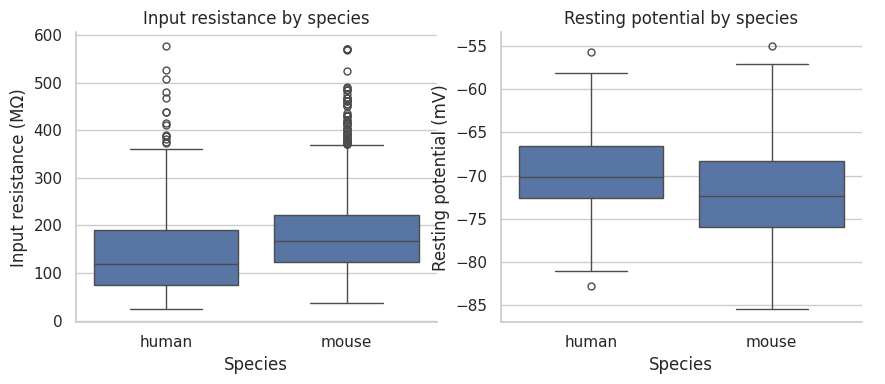

In [35]:
q1_data = neurons.melt(id_vars="species",
                       value_vars=["input_resistance_mohm", "resting_potential_mv"],
                       var_name="property", value_name="value")

g = sns.catplot(data=q1_data, x="species", y="value", col="property",
                kind="box", sharey=False, height=4, aspect=1.1)
g.axes[0, 0].set_title("Input resistance by species")
g.axes[0, 0].set_ylabel("Input resistance (MΩ)")
g.axes[0, 1].set_title("Resting potential by species")
g.axes[0, 1].set_ylabel("Resting potential (mV)")
g.set_xlabels("Species")
plt.show()

Human neurons have lower input resistance than mouse neurons (median 118 vs. 167 MΩ), and their values are more spread out. Resting potentials overlap almost completely (median −70 vs. −72 mV). So the two species differ in how strongly their cells respond to input current, but not in their resting state. Part of this difference may come from the human and mouse cells being recorded in different brain regions.

## Plot 2 (distribution, Q2): spike shape and firing rate, spiny vs. aspiny
These boxplots use `neurons_2groups`, so sparsely spiny cells are left out. Firing rate is shown on a log scale because a few cells fire much faster than the rest.

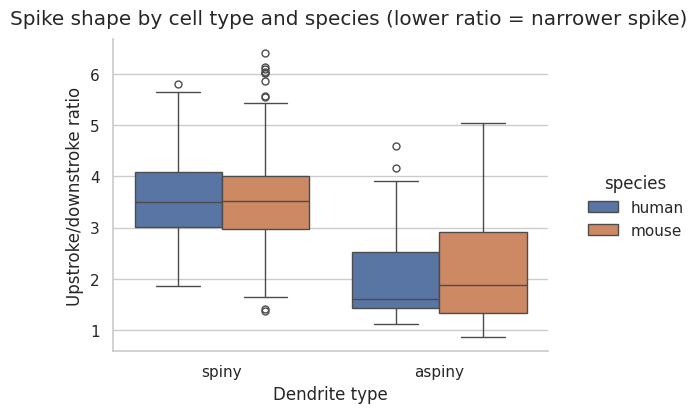

In [36]:
g = sns.catplot(data=neurons_2groups, x="dendrite_type", y="upstroke_downstroke_ratio",
                hue="species", kind="box", height=4, aspect=1.3)
g.set_axis_labels("Dendrite type", "Upstroke/downstroke ratio")
g.figure.suptitle("Spike shape by cell type and species (lower ratio = narrower spike)", y=1.03)
plt.show()

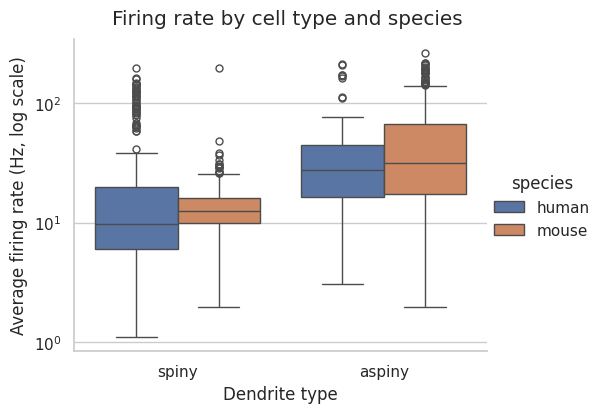

In [37]:
g = sns.catplot(data=neurons_2groups, x="dendrite_type", y="firing_rate_hz",
                hue="species", kind="box", height=4, aspect=1.3)
g.set(yscale="log")
g.set_axis_labels("Dendrite type", "Average firing rate (Hz, log scale)")
g.figure.suptitle("Firing rate by cell type and species", y=1.03)
plt.show()

In both species, aspiny cells have a much lower upstroke/downstroke ratio than spiny cells (median about 1.6–1.9 vs. 3.5), which means narrower spikes. They also fire faster (median about 27–32 Hz vs. 10–13 Hz). The pattern is the same in humans and mice, so for these two properties cell type matters more than species.

## Plot 3 (additional, Q3): median properties across cortical layers
The next cell reshapes `layer_summary` from Part 2 and draws one line per species for each property. Layers go from the surface (1) to the deepest layer (6).

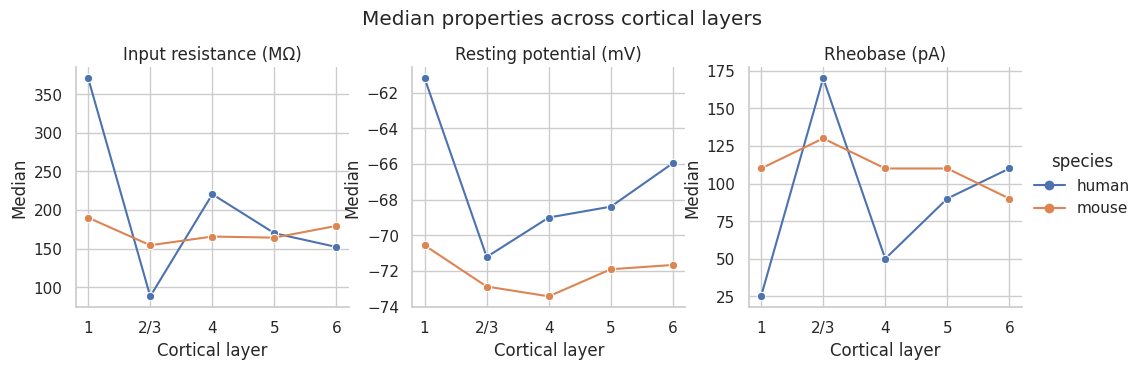

In [38]:
layer_data = layer_summary.reset_index().melt(id_vars=["species", "layer"],
                                              var_name="property", value_name="median")
units = {"input_resistance_mohm": "Input resistance (MΩ)",
         "resting_potential_mv": "Resting potential (mV)",
         "rheobase_pa": "Rheobase (pA)"}

g = sns.relplot(data=layer_data, x="layer", y="median", hue="species", col="property",
                kind="line", marker="o", facet_kws={"sharey": False}, height=3.5)
for prop, ax in g.axes_dict.items():
    ax.set_title(units[prop])
    ax.set_ylabel("Median")
g.set_xlabels("Cortical layer")
g.figure.suptitle("Median properties across cortical layers", y=1.05)
plt.show()

Mouse medians stay fairly flat across layers (input resistance 154–190 MΩ, resting potential about −71 to −73 mV). Human medians change much more, for example input resistance goes from 88 MΩ in layer 2/3 to 370 MΩ in layer 1. However, human layers 1 and 6 have only 10 and 17 cells, so those points are not reliable.

## Plot 4 (relationship, Q4): input resistance vs. firing rate
`lmplot` draws each cell as a point and adds a trend line for each species, with one panel per dendrite type. Cells without a firing rate are left out.

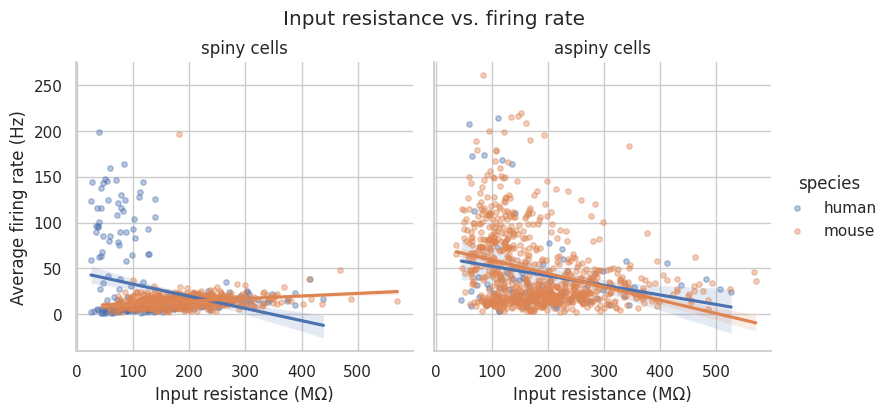

In [39]:
q4_data = neurons_2groups.dropna(subset=["firing_rate_hz"])

g = sns.lmplot(data=q4_data, x="input_resistance_mohm", y="firing_rate_hz",
               hue="species", col="dendrite_type", height=4,
               scatter_kws={"alpha": 0.4, "s": 15})
g.set_axis_labels("Input resistance (MΩ)", "Average firing rate (Hz)")
g.set_titles("{col_name} cells")
g.figure.suptitle("Input resistance vs. firing rate", y=1.03)
plt.show()

The trend lines are weak in all four groups. Input resistance and firing rate are slightly negatively related in human aspiny (−0.24), human spiny (−0.28) and mouse aspiny cells (−0.33), but slightly positively related in mouse spiny cells (+0.22). The relationship depends on cell type, and because this is observational data, it shows an association, not a cause.

# Conclusion

Neurons in this dataset differ more by cell type than by species. In both humans and mice, aspiny cells have narrower spikes and fire faster than spiny cells. Between species, the clearest difference is input resistance, which is lower in human neurons (median 118 vs. 167 MΩ), while resting potential is almost the same. Human cells also vary more across cortical layers than mouse cells, although some human layers have very few cells.

These are associations in observational data. Differences between species may partly come from the different brain regions the cells were recorded in, and the small human groups make some results less certain.